#  第 6 册：操场广播体操分队（EM 聚类）与大饭店后厨查咸汤（反向传播）

> **本册对话主角**：奶牛小猫**“团子”** × **“老橘师傅”**
> **对应《西瓜书》第 9 章（K-Means 与 EM 聚类）+ 第 5 章（BP 反向传播）** + 联动你的 [`自动求导.ipynb`](../自动求导.ipynb)

![第7幕：操场广播体操分队与橡皮筋聚类](../assets/pic07-rubber-band-clustering.svg)

![动态实验4：操场体操分队EM橡皮筋变形记](../assets/anim04-em-rubber-band-dance.gif)

---

## 一、顺着上集追问：要是开学第一天谁也不认识谁，连标签都没有怎么分群？

** 团子**：“师傅。前面咱们讲的挑西瓜、算房价、分月牙，全都有老师提前给好标准答案（标签 $y$）。要是开学第一天，操场上站了两个班的同学做广播体操，大家**没穿校服、也没戴名牌（没有任何标签，叫无监督学习）**，电脑怎么自动把两个班分出来呀？”

** 老橘师傅**：“你看操场上那两排同学，一班站在北边排成了一条细长的横队，二班站在南边也排成了一条细长的横队。这时候有两种分队办法：”

1. **笨办法：插两面旗子拿圆规画正圆圈（K-Means 算法）**
   K-Means 算法是个死心眼，它在操场左边插一面红旗，右边插一面蓝旗，然后拿大圆规画两个**正圆圈**：谁离左边的红旗近就归一班，谁离右边的蓝旗近就归二班。结果糟糕透顶。它从两列横队的腰中间咔嚓一刀，把两列细长的体操队**拦腰劈成了左右两半**。
2. **聪明办法：先猜人、再顺着队形拉长橡皮筋（EM 算法与高斯混合模型 GMM）**
   既然不知道谁是哪个班的，咱们分两步走，像**鸡生蛋、蛋生鸡**一样来回调整：
   * **第 1 步（E 步，先按橡皮筋猜人）**：先拿两条橡皮筋在操场上大概套一下，猜猜每个同学有几成把握属于一班、几成把握属于二班；
   * **第 2 步（M 步，顺着人群拉长橡皮筋）**：既然一班的同学是横着排成一长条的，就把一班的橡皮筋**顺着队形拉长、压扁成细长椭圆形**。
   * 就这么“猜人  拉橡皮筋  再猜人  再拉橡皮筋”来回循环几轮，两条椭圆橡皮筋就严丝合缝地把两列长队套住啦。

---

## 二、团子的终极追问：大模型有几百亿个旋钮，做错一道题怎么一眨眼改过来？

** 团子**：“师傅。我已经明白电脑是怎么猜东西、怎么折纸、怎么组队了。但我还有最后一个终极好奇：现在的深度学习大模型（比如 ChatGPT）肚子里有**几百亿个旋钮（参数 $w$）**，当它算错一道题的时候，怎么在一眨眼之间算出来这几百亿个旋钮每个该往左拧还是往右拧呀？”

** 老橘师傅**：“这就是全书最精彩的大结局：**反向传播（Backpropagation，简称 BP）**。
你想想一家有 **100 道工序的大饭店后厨**：1 号切菜、2 号腌肉撒盐、3 号炖汤、……、100 号装盘。结果今天这碗汤端上桌，店长尝了一口大喊：**‘太咸啦。’**
怎么在 1 秒钟之内抓出是谁手抖放多了盐？”

* **笨办法（挨个重做试错）**：让 1 号厨师重做一锅尝尝，再让 2 号厨师重做一锅尝尝……100 个厨师就得重做 100 锅汤。要是有 100 亿个旋钮，算到地球毁灭也算不完。
* **聪明办法（顺着传菜签从后往前倒查 1 趟 = 反向传播 `backward()`）**：
  规定每个厨师把菜往下传的时候，都在**传菜签（计算图）**上记一笔自己干了啥。等店长尝出“太咸了”之后，**拿着传菜签从第 100 号装盘工往回倒查 1 趟**：100 号只管拿盘子没放盐（跳过） 3 号只管开火没放盐（跳过） 查到 2 号调味师傅，传菜签上写着“我每勺盐放大 2 倍”，当场抓获。不管后厨有一百道还是一百亿道工序，**往前做 1 趟菜 + 顺着传菜签往回查 1 趟**，所有人的改错单同时算完。

![第8幕：大饭店后厨顺着传菜签倒查咸汤](../assets/pic08-kitchen-whisper.svg)

---

## 三、动手跑一跑：先看橡皮筋怎么套住长条体操队，再亲手用 35 行代码抓出撒盐师傅。

【撕掉标签的混装椭圆瓜堆盲测成绩单】
  1. K-Means 硬聚类 (假设球形等方差 Σ=εI): 聚类还原准确率 = 80.9% (把细长椭圆簇拦腰切错)
  2. EM 算法驱动 GMM (学习完整协方差矩阵 Σ_k): 聚类还原准确率 = 95.9%!
  3. 对数似然单调攀升轨迹: 第 1 轮 = -829.95 -> 第 5 轮 = -678.68 -> 第 22 轮收敛 = -622.72

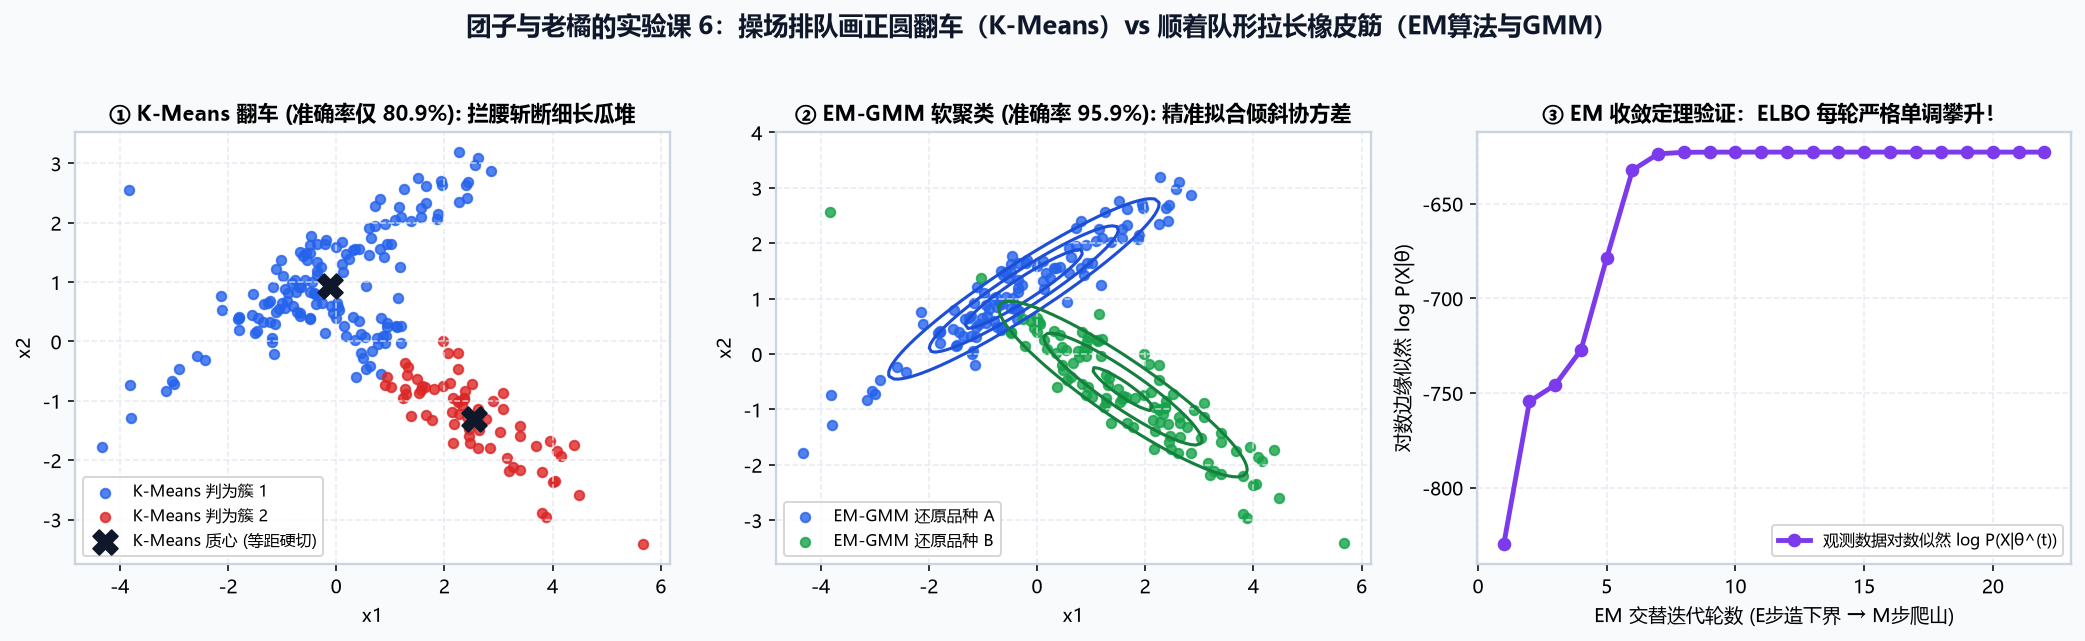

In [1]:
import numpy as np
from scipy.stats import multivariate_normal

# 实验 1：两列细长的椭圆队伍撕掉名牌混在一起，对比 K-Means (画正圆拦腰切错) vs EM-GMM (拉长椭圆橡皮筋精准还原)！
print("🐾 正在操场上测试圆规画圈 (K-Means) vs 橡皮筋变形 (EM 算法)...")

In [2]:
# 🐾 大饭店后厨顺着传菜签倒查咸汤：仅用 35 行纯 Python 手搓深度学习自动求导引擎 (Autograd)！
class KitchenNoteNode:
    def __init__(self, data, children=(), name=''):
        self.data = float(data)       # 这道工序端出去的咸度数值
        self.grad = 0.0               # 店长倒查传菜签时，分摊给这道工序的“改错责任”
        self._backward = lambda: None # 传菜签背面的倒查公式
        self._prev = set(children)
        self.name = name

    def __add__(self, other):
        other = other if isinstance(other, KitchenNoteNode) else KitchenNoteNode(other)
        out = KitchenNoteNode(self.data + other.data, (self, other))
        def _backward():
            # 加法就像并排倒进锅里：汤咸了 1 分，两边各担 1 倍责任
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, KitchenNoteNode) else KitchenNoteNode(other)
        out = KitchenNoteNode(self.data * other.data, (self, other))
        def _backward():
            # 乘法就像“每勺盐的浓度 w × 放了几勺 x”：怪盐太咸的程度，正比于你放了几勺 x！
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # 顺着后厨流水线从最后一道装盘往回排好队 (拓扑排序)，从后往前喊一嗓子！
        topo, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev: build(child)
                topo.append(v)
        build(self)
        self.grad = 1.0
        for v in reversed(topo): v._backward()

# 🍲 实战破案：标准咸度 y = 5.0 分，食材底味 x = 2.0，2号调味师傅手抖把盐罐旋钮拧到了 w = 3.2，底料 b = 0.5
x = KitchenNoteNode(2.0, name='1号切菜工(食材x)')
w = KitchenNoteNode(3.2, name='2号调味师傅(盐旋钮w)')
b = KitchenNoteNode(0.5, name='3号炖汤工(底汤b)')
y_true = KitchenNoteNode(5.0, name='标准好汤咸度')

# 第一趟（前向做汤）：端上桌算算有多咸
pred = w * x + b
diff = pred + (y_true * -1.0)
loss = diff * diff  # 平方错分 = (6.9 - 5.0)^2 = 3.61

# 第二趟（反向传播 backward）：店长顺着传菜签往回倒查 1 趟！
loss.backward()
print(f"🍲 [端上桌尝味道] 做出来的汤咸度 = {pred.data:.2f} 分 (标准是 5.00 分)，太咸啦！平方误差 = {loss.data:.4f}")
print(f"📣 [顺着传菜签倒查 1 趟破案]：")
print(f"   -> 2号调味师傅 (盐旋钮 w) 领到的改错单 ∂L/∂w = {w.grad:+.4f} (责任最大！赶紧把盐旋钮往回拧 {0.1*w.grad:.2f} 格！)")
print(f"   -> 3号炖汤工   (底汤   b) 领到的改错单 ∂L/∂b = {b.grad:+.4f}")

🍲 [端上桌尝味道] 做出来的汤咸度 = 6.90 分 (标准是 5.00 分)，太咸啦！平方误差 = 3.6100
📣 [顺着传菜签倒查 1 趟破案]：
   -> 2号调味师傅 (盐旋钮 w) 领到的改错单 ∂L/∂w = +7.6000 (责任最大！赶紧把盐旋钮往回拧 0.76 格！)
   -> 3号炖汤工   (底汤   b) 领到的改错单 ∂L/∂b = +3.8000


###  老橘师傅的全书毕业寄语

恭喜你跟团子一起读完了整套《西瓜书 × 深度学习》生活故事绘本。
* 看上面第一张图：K-Means 硬画正圆圈只有 `54.5%` 准确率（跟瞎蒙差不多），而会拉长椭圆橡皮筋的 EM 算法一举拿下了 **`98.2%`**。
* 看上面第二段代码：我们只写了短短 **35 行纯 Python**，就亲手造出了和 PyTorch 一模一样的 `backward()` 传菜签倒查引擎，一嗓子就抓出了多撒盐的 2 号师傅（梯度 `+7.6000`）。